# Analyse de sentiments avec BERT sur IMDb



## 1. Installation et imports

In [1]:
!pip install -q transformers datasets evaluate accelerate scikit-learn lime matplotlib seaborn bertviz

  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done


In [2]:
import numpy as np
import pandas as pd
import torch
import matplotlib.pyplot as plt
import seaborn as sns
from datasets import load_dataset
from transformers import (AutoTokenizer, AutoModelForSequenceClassification,
                          DataCollatorWithPadding, TrainingArguments, Trainer, pipeline)
from sklearn.metrics import (accuracy_score, precision_recall_fscore_support,
                             confusion_matrix, classification_report)

SEED = 42
device = 0 if torch.cuda.is_available() else -1
print("GPU disponible :", torch.cuda.is_available())

GPU disponible : True


## 2. Chargement et exploration des données

In [4]:
dataset = load_dataset("stanfordnlp/imdb")
print(dataset)
print("\nExemple :", dataset["train"][0]["text"][:300], "...")
print("Label :", dataset["train"][0]["label"], "(0 = négatif, 1 = positif)")

README.md:   0%|          | 0.00/7.81k [00:00<?, ?B/s]

plain_text/train-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B / 21.0MB            

plain_text/train-00000-of-00001.parquet: downloading bytes:           |  0.00B            

plain_text/test-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B / 20.5MB            

plain_text/test-00000-of-00001.parquet: downloading bytes:           |  0.00B            

plain_text/unsupervised-00000-of-00001.p(…): reconstructing file:   0%|          |  0.00B / 42.0MB            

plain_text/unsupervised-00000-of-00001.p(…): downloading bytes:           |  0.00B            

Generating train split:   0%|          | 0/25000 [00:00<?, ? examples/s]

Generating test split:   0%|          | 0/25000 [00:00<?, ? examples/s]

Generating unsupervised split:   0%|          | 0/50000 [00:00<?, ? examples/s]

DatasetDict({
    train: Dataset({
        features: ['text', 'label'],
        num_rows: 25000
    })
    test: Dataset({
        features: ['text', 'label'],
        num_rows: 25000
    })
    unsupervised: Dataset({
        features: ['text', 'label'],
        num_rows: 50000
    })
})

Exemple : I rented I AM CURIOUS-YELLOW from my video store because of all the controversy that surrounded it when it was first released in 1967. I also heard that at first it was seized by U.S. customs if it ever tried to enter this country, therefore being a fan of films considered "controversial" I really h ...
Label : 0 (0 = négatif, 1 = positif)


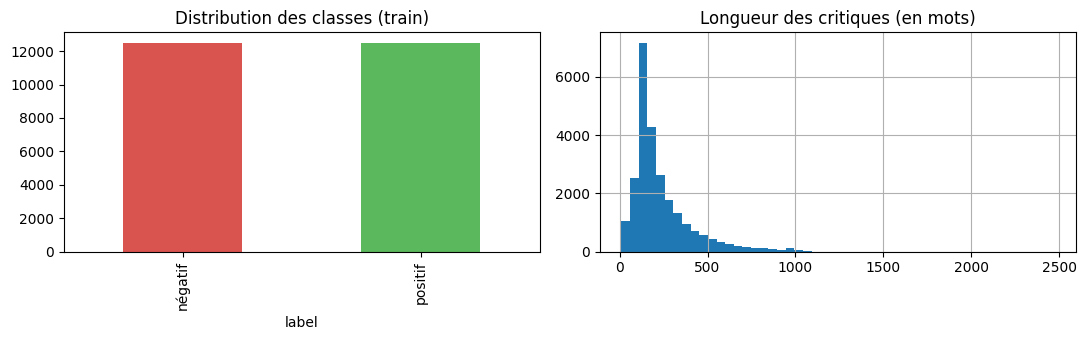

count    25000.000000
mean       233.787200
std        173.733032
min         10.000000
25%        127.000000
50%        174.000000
75%        284.000000
max       2470.000000
Name: n_mots, dtype: float64


In [5]:
df = dataset["train"].to_pandas()
df["n_mots"] = df["text"].str.split().str.len()

fig, ax = plt.subplots(1, 2, figsize=(11, 3.5))
df["label"].map({0: "négatif", 1: "positif"}).value_counts().plot.bar(ax=ax[0], color=["#d9534f", "#5cb85c"])
ax[0].set_title("Distribution des classes (train)")
df["n_mots"].hist(bins=50, ax=ax[1])
ax[1].set_title("Longueur des critiques (en mots)")
plt.tight_layout(); plt.show()
print(df["n_mots"].describe())

## 3. Sous-échantillon



In [6]:
N_TRAIN, N_TEST = 10000, 2000
train_ds = dataset["train"].shuffle(seed=SEED).select(range(N_TRAIN))
test_ds  = dataset["test"].shuffle(seed=SEED).select(range(N_TEST))
print(len(train_ds), len(test_ds))

10000 2000


## 4. Baseline : pipeline pré-entraîné



In [9]:
texts = list(test_ds["text"])
raw = baseline(texts, truncation=True, max_length=256, batch_size=32)
base_pred = np.array([1 if r["label"] == "POSITIVE" else 0 for r in raw])
y_true = np.array(list(test_ds["label"]))

def scores(y, p):
    prec, rec, f1, _ = precision_recall_fscore_support(y, p, average="binary")
    return {"accuracy": accuracy_score(y, p), "precision": prec, "recall": rec, "f1": f1}

res_base = scores(y_true, base_pred)
print("Baseline :", {k: round(v, 4) for k, v in res_base.items()})

Baseline : {'accuracy': 0.8795, 'precision': 0.8982, 'recall': 0.856, 'f1': 0.8766}


## 5. Tokenisation pour le fine-tuning



In [12]:
MODEL_NAME = "bert-base-uncased"
tokenizer = AutoTokenizer.from_pretrained(MODEL_NAME)

def tokenize(batch):
    return tokenizer(batch["text"], truncation=True, max_length=256)

train_tok = train_ds.map(tokenize, batched=True)
test_tok  = test_ds.map(tokenize, batched=True)
collator = DataCollatorWithPadding(tokenizer=tokenizer)

print(tokenizer.tokenize("This movie was unbelievably good!"))

config.json:   0%|          | 0.00/570 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/48.0 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/232k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/466k [00:00<?, ?B/s]

Map:   0%|          | 0/10000 [00:00<?, ? examples/s]

Map:   0%|          | 0/2000 [00:00<?, ? examples/s]

['this', 'movie', 'was', 'un', '##bel', '##ie', '##va', '##bly', 'good', '!']


## 6. Fine-tuning de BERT



In [13]:
model = AutoModelForSequenceClassification.from_pretrained(
    MODEL_NAME, num_labels=2,
    id2label={0: "NEGATIVE", 1: "POSITIVE"}, label2id={"NEGATIVE": 0, "POSITIVE": 1})

def compute_metrics(eval_pred):
    logits, labels = eval_pred
    preds = np.argmax(logits, axis=-1)
    return scores(labels, preds)

args = TrainingArguments(
    output_dir="bert-imdb",
    learning_rate=2e-5,
    per_device_train_batch_size=16,
    per_device_eval_batch_size=32,
    num_train_epochs=2,
    weight_decay=0.01,
    eval_strategy="epoch",        # si erreur : remplacer par evaluation_strategy="epoch"
    save_strategy="epoch",
    load_best_model_at_end=True,
    fp16=torch.cuda.is_available(),
    seed=SEED,
    report_to="none",
)

trainer = Trainer(model=model, args=args, train_dataset=train_tok, eval_dataset=test_tok,
                  data_collator=collator, compute_metrics=compute_metrics)
trainer.train()

model.safetensors: reconstructing file:   0%|          |  0.00B /  440MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[transformers] BertForSequenceClassification LOAD REPORT from: bert-base-uncased
Key                                        | Status     | 
-------------------------------------------+------------+-
cls.predictions.transform.LayerNorm.weight | UNEXPECTED | 
cls.predictions.transform.dense.bias       | UNEXPECTED | 
cls.predictions.bias                       | UNEXPECTED | 
cls.seq_relationship.weight                | UNEXPECTED | 
cls.seq_relationship.bias                  | UNEXPECTED | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED | 
cls.predictions.transform.dense.weight     | UNEXPECTED | 
classifier.bias                            | MISSING    | 
classifier.weight                          | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


Epoch,Training Loss,Validation Loss,Accuracy,Precision,Recall,F1
1,0.341587,0.231879,0.904500,0.880527,0.936000,0.907416
2,0.181058,0.263535,0.918500,0.914767,0.923000,0.918865


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

[transformers] There were missing keys in the checkpoint model loaded: ['bert.embeddings.LayerNorm.weight', 'bert.embeddings.LayerNorm.bias', 'bert.encoder.layer.0.attention.output.LayerNorm.weight', 'bert.encoder.layer.0.attention.output.LayerNorm.bias', 'bert.encoder.layer.0.output.LayerNorm.weight', 'bert.encoder.layer.0.output.LayerNorm.bias', 'bert.encoder.layer.1.attention.output.LayerNorm.weight', 'bert.encoder.layer.1.attention.output.LayerNorm.bias', 'bert.encoder.layer.1.output.LayerNorm.weight', 'bert.encoder.layer.1.output.LayerNorm.bias', 'bert.encoder.layer.2.attention.output.LayerNorm.weight', 'bert.encoder.layer.2.attention.output.LayerNorm.bias', 'bert.encoder.layer.2.output.LayerNorm.weight', 'bert.encoder.layer.2.output.LayerNorm.bias', 'bert.encoder.layer.3.attention.output.LayerNorm.weight', 'bert.encoder.layer.3.attention.output.LayerNorm.bias', 'bert.encoder.layer.3.output.LayerNorm.weight', 'bert.encoder.layer.3.output.LayerNorm.bias', 'bert.encoder.layer.4.atte

TrainOutput(global_step=1250, training_loss=0.24213585205078125, metrics={'train_runtime': 287.7498, 'train_samples_per_second': 69.505, 'train_steps_per_second': 4.344, 'total_flos': 2631110553600000.0, 'train_loss': 0.24213585205078125, 'epoch': 2.0})

## 7. Évaluation et comparaison

In [14]:
output = trainer.predict(test_tok)
ft_pred = np.argmax(output.predictions, axis=-1)
res_ft = scores(y_true, ft_pred)

comparison = pd.DataFrame({"Baseline (DistilBERT SST-2)": res_base,
                           "BERT fine-tuné (IMDb)": res_ft}).T.round(4)
display(comparison)
print(classification_report(y_true, ft_pred, target_names=["négatif", "positif"]))

,accuracy,precision,recall,f1
Baseline (DistilBERT SST-2),0.8795,0.8982,0.856,0.8766
BERT fine-tuné (IMDb),0.9045,0.8805,0.936,0.9074


              precision    recall  f1-score   support

     négatif       0.93      0.87      0.90      1000
     positif       0.88      0.94      0.91      1000

    accuracy                           0.90      2000
   macro avg       0.91      0.90      0.90      2000
weighted avg       0.91      0.90      0.90      2000



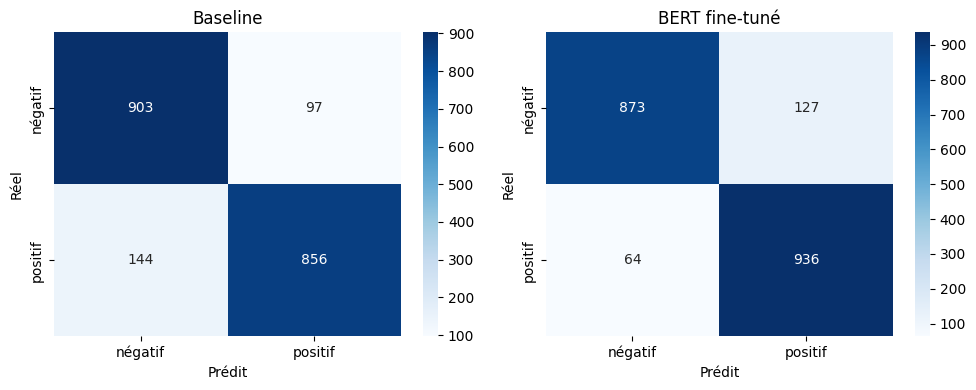

In [15]:
fig, ax = plt.subplots(1, 2, figsize=(10, 4))
for a, pred, title in zip(ax, [base_pred, ft_pred], ["Baseline", "BERT fine-tuné"]):
    cm = confusion_matrix(y_true, pred)
    sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", ax=a,
                xticklabels=["négatif", "positif"], yticklabels=["négatif", "positif"])
    a.set_title(title); a.set_xlabel("Prédit"); a.set_ylabel("Réel")
plt.tight_layout(); plt.show()

## 8. Interprétation
### 8.1 Analyse des erreurs

In [16]:
probs = torch.softmax(torch.tensor(output.predictions), dim=-1).numpy()
errors = pd.DataFrame({"text": test_ds["text"], "reel": y_true, "predit": ft_pred,
                       "confiance": probs.max(axis=1)})
errors = errors[errors["reel"] != errors["predit"]].sort_values("confiance", ascending=False)
print(f"{len(errors)} erreurs sur {len(y_true)} critiques\n")

for _, r in errors.head(5).iterrows():
    print(f"[réel={r.reel} | prédit={r.predit} | confiance={r.confiance:.2f}]")
    print(r.text[:400], "...\n")

191 erreurs sur 2000 critiques

[réel=0 | prédit=1 | confiance=0.99]
This is, without a doubt, the most hilarious movie I've ever seen. Seriously, if the makers of this movie are ever discovered, they'll put guys like Jim Carrey out of a job. Rent "Jack-O" tonight! Believe me, you won't regret it! ...

[réel=0 | prédit=1 | confiance=0.99]
Going into the movie with the right expectations, I somewhat liked this movie. Like most reviewers who have seen this movie, I fully agree that the plot was razor thin, clichéd, and I could predict every plot twist from the very beginning of the movie. But, the dancing sequences were VERY well done, and I really enjoyed the fusion of classical and hip-hop dance (both which I enjoy watching). The m ...

[réel=1 | prédit=0 | confiance=0.98]
This is not the kind of movie that really merits critical attention. It's not going to win any Oscars - it's really not a very good movie at all. Heck, it's not even really a movie - just a string of short disgusting

### 8.2 Importance des mots avec LIME

In [17]:
from lime.lime_text import LimeTextExplainer

def predict_proba(texts):
    inputs = tokenizer(list(texts), return_tensors="pt", truncation=True,
                       max_length=256, padding=True).to(trainer.model.device)
    with torch.no_grad():
        logits = trainer.model(**inputs).logits
    return torch.softmax(logits, dim=-1).cpu().numpy()

explainer = LimeTextExplainer(class_names=["négatif", "positif"])
text = "The plot was predictable, but the acting was brilliant and I loved the ending."
exp = explainer.explain_instance(text, predict_proba, num_features=8, num_samples=500)
exp.show_in_notebook(text=True)

### 8.3 Visualisation de l'attention avec BertViz

In [20]:
from bertviz import head_view

trainer.save_model("bert-imdb-final")
model_eager = AutoModelForSequenceClassification.from_pretrained(
    "bert-imdb-final", attn_implementation="eager").to(trainer.model.device)
model_eager.eval()

sentence = "The movie was not good at all."
inputs = tokenizer(sentence, return_tensors="pt").to(model_eager.device)
with torch.no_grad():
    attn = model_eager(**inputs, output_attentions=True).attentions
tokens = tokenizer.convert_ids_to_tokens(inputs["input_ids"][0])
head_view([a.cpu() for a in attn], tokens)

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/201 [00:00<?, ?it/s]

<IPython.core.display.Javascript object>

## 9. Tester le modèle sur vos propres phrases

In [21]:
my_clf = pipeline("sentiment-analysis", model=trainer.model, tokenizer=tokenizer,
                  device=0 if torch.cuda.is_available() else -1)
for t in ["I absolutely loved this film, a masterpiece!",
          "A complete waste of time. Awful script.",
          "Oh great, another two hours of my life I will never get back."]:   # ironie !
    print(t, "->", my_clf(t)[0])

I absolutely loved this film, a masterpiece! -> {'label': 'POSITIVE', 'score': 0.9898107051849365}
A complete waste of time. Awful script. -> {'label': 'NEGATIVE', 'score': 0.9768908023834229}
Oh great, another two hours of my life I will never get back. -> {'label': 'POSITIVE', 'score': 0.5748423933982849}
